# Portuguese Bank Term Deposit — Data Analysis & Prediction
# By: Suchitra Thanumalayan

- **Part 1:** Data analysis report
- **Part 2:** Predictive model to find which customers will subscribe to a term deposit
- **Part 3:** Suggestions for the bank marketing team on which customers to focus on

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
# the file uses ';' as the separator instead of ','
df=pd.read_csv("bank-additional-full.csv", sep=';')
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


# Part 1: Data Analysis Report
## 1. Basic Checks

In [3]:
df.shape

(41188, 21)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [5]:
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [6]:
df.isnull().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [7]:
# missing values are written as 'unknown' instead of being empty
(df == 'unknown').sum()

age                  0
job                330
marital             80
education         1731
default           8597
housing            990
loan               990
contact              0
month                0
day_of_week          0
duration             0
campaign             0
pdays                0
previous             0
poutcome             0
emp.var.rate         0
cons.price.idx       0
cons.conf.idx        0
euribor3m            0
nr.employed          0
y                    0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(12)

In [9]:
df.nunique()

age                 78
job                 12
marital              4
education            8
default              3
housing              3
loan                 3
contact              2
month               10
day_of_week          5
duration          1544
campaign            42
pdays               27
previous             8
poutcome             3
emp.var.rate        10
cons.price.idx      26
cons.conf.idx       26
euribor3m          316
nr.employed         11
y                    2
dtype: int64

In [10]:
df['y'].value_counts(normalize=True) * 100

y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64

In [11]:
(df['pdays'] == 999).mean() * 100

np.float64(96.32174419733903)

**Observations**
- The data has **41,188 rows and 21 columns**. Each row is one phone call to a customer during the bank's term deposit campaigns (May 2008 to November 2010).
- The file uses `;` as a separator, so it has to be read with `sep=';'`.
- There are **no empty (null) values**, but missing answers are written as **`'unknown'`**: `default` (8,597 rows, about 21%), `education` (1,731), `housing` and `loan` (990 each), `job` (330) and `marital` (80).
- `default` is almost always `'no'` or `'unknown'`; only 3 customers have `'yes'`.
- There are **12 duplicate rows**.
- The target `y` is **imbalanced**: only **11.3%** of customers subscribed and 88.7% did not.
- `pdays` is **999 for 96.3%** of rows, which is a code meaning "never contacted before", not a real number of days.
- `duration` (call length) is only known **after** the call is over, so it can't be used to decide who to call.
- `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m` and `nr.employed` are economic indicators for the month of the call, not information about the customer.

## Cleaning The Data

In [12]:
# remove duplicate rows
df = df.drop_duplicates()

# target column: 1 = subscribed, 0 = did not subscribe
df['y'] = (df['y'] == 'yes').astype(int)

# pdays = 999 means the customer was never contacted before, so make a simple yes/no flag
df['PREV CONTACTED'] = (df['pdays'] != 999).astype(int)
df = df.drop(columns=['pdays'])

# age groups for the plots
df['AGE GROUP'] = pd.cut(df['age'], bins=[16, 25, 30, 40, 50, 60, 100],
                         labels=['17-25', '26-30', '31-40', '41-50', '51-60', '60+'])

df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,PREV CONTACTED,AGE GROUP
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0,51-60
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0,51-60
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0,31-40
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0,31-40
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0,51-60


In [13]:
df.shape

(41176, 22)

After cleaning there are **no duplicate rows**. The `'unknown'` values are kept as their own category, because they are a real answer ("the customer did not say") and removing them would throw away thousands of rows.

## 2. Histogram

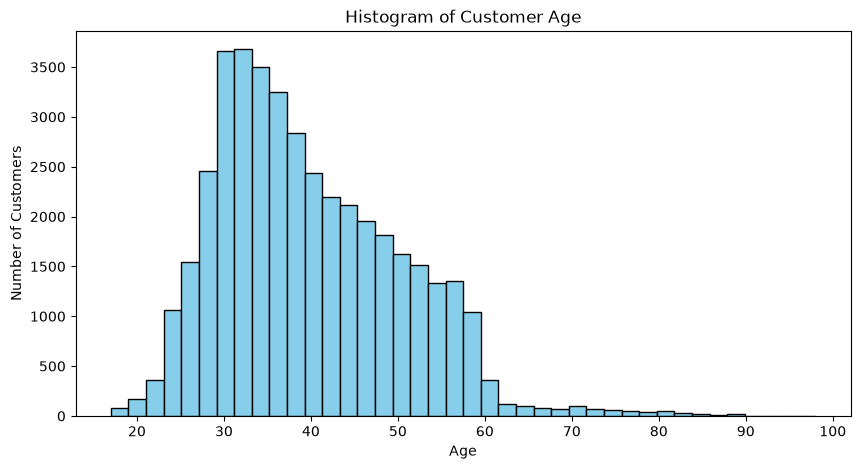

In [14]:
plt.figure(figsize=(10,5))
plt.hist(df['age'], bins=40, color='skyblue', edgecolor='black')
plt.title('Histogram of Customer Age')
plt.xlabel('Age')
plt.ylabel('Number of Customers')
plt.show()

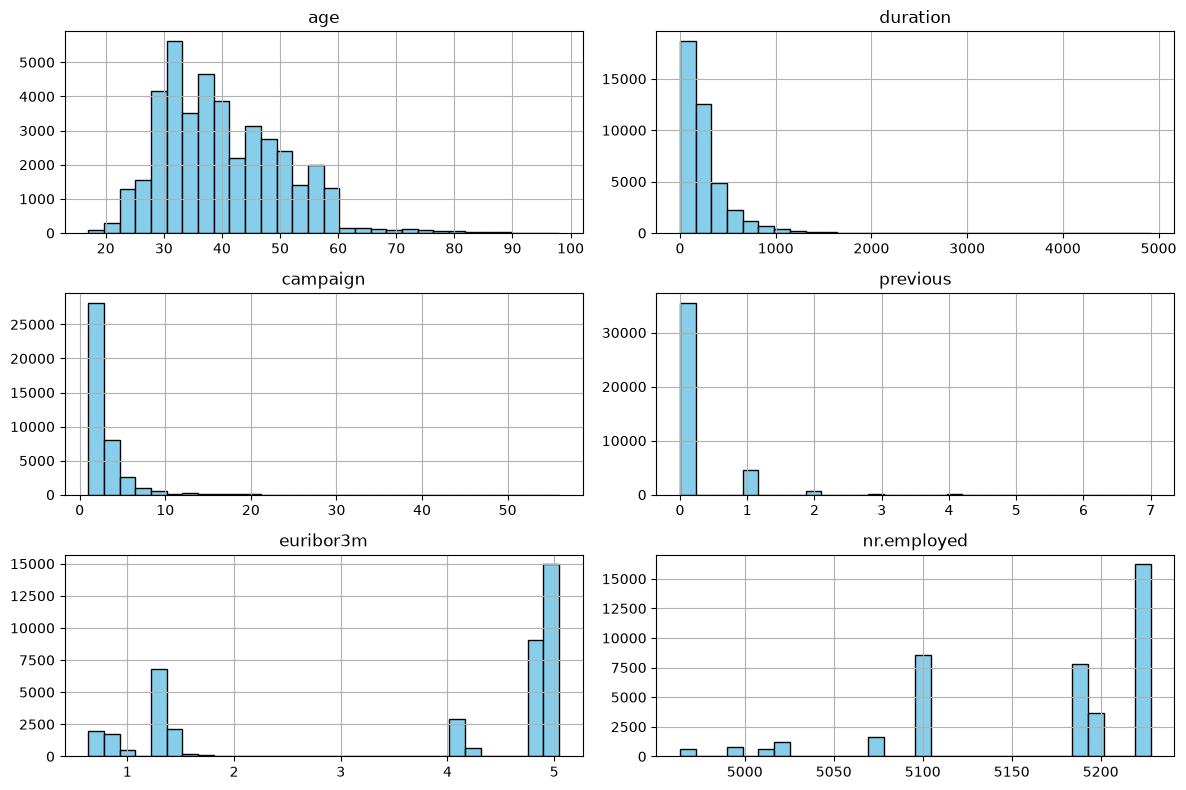

In [15]:
df[['age', 'duration', 'campaign', 'previous', 'euribor3m', 'nr.employed']].hist(figsize=(12,8), bins=30, color='skyblue', edgecolor='black')
plt.tight_layout()
plt.show()

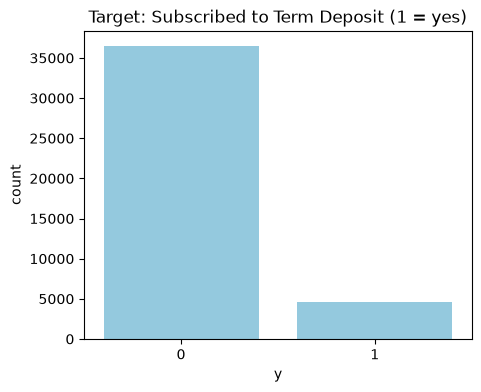

In [16]:
plt.figure(figsize=(5,4))
sns.countplot(data=df, x='y', color='skyblue')
plt.title('Target: Subscribed to Term Deposit (1 = yes)')
plt.show()

**Insights:** Most customers are between 30 and 50 years old, with very few over 60. Call duration and number of calls (`campaign`) are strongly right-skewed: most calls are short and most customers were called only 1-3 times, but a few were called more than 40 times. The economic columns only take a few values because they change by month, not by customer. The target is very imbalanced (about 1 yes for every 8 no's).

## 3. Relational Plots

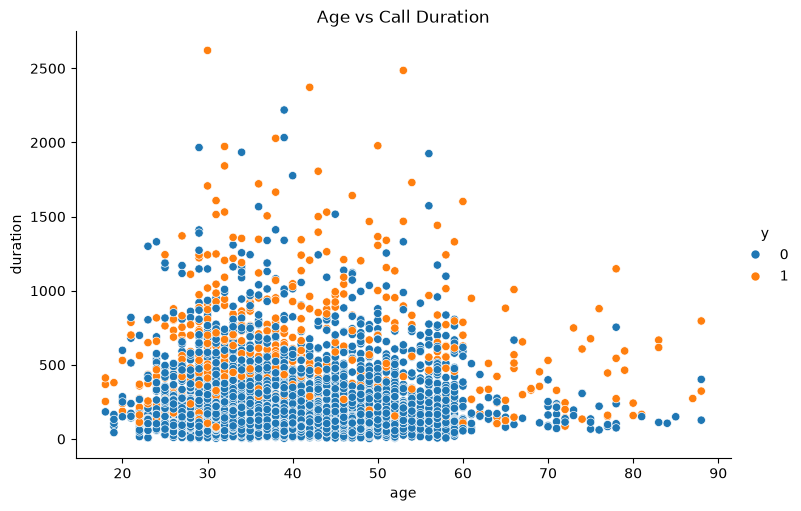

In [17]:
sns.relplot(data=df.sample(5000, random_state=1), x='age', y='duration', hue='y', height=5, aspect=1.5)
plt.title('Age vs Call Duration')
plt.show()

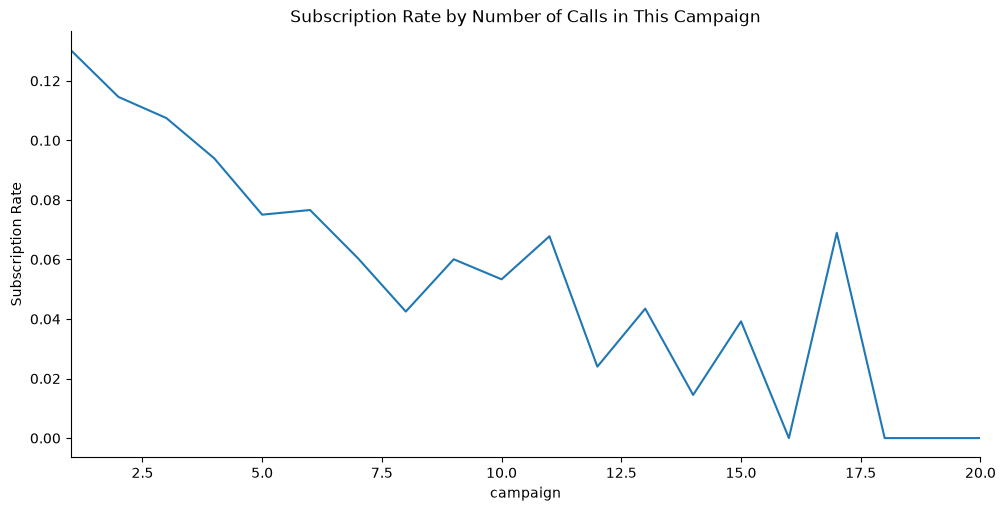

In [18]:
sns.relplot(data=df, x='campaign', y='y', kind='line', errorbar=None, height=5, aspect=2)
plt.title('Subscription Rate by Number of Calls in This Campaign')
plt.xlim(1, 20)
plt.ylabel('Subscription Rate')
plt.show()

**Insights:** Customers who subscribed (orange) had much longer calls: the median call is about **7.5 minutes for a yes and 2.7 minutes for a no**. Age does not change this much. The subscription rate **drops steadily with each extra call**: 13% on the first call, about 7.5% by the 5th call, and almost zero after 15 calls.

## 4. Pair Plot (Multivariate Analysis)

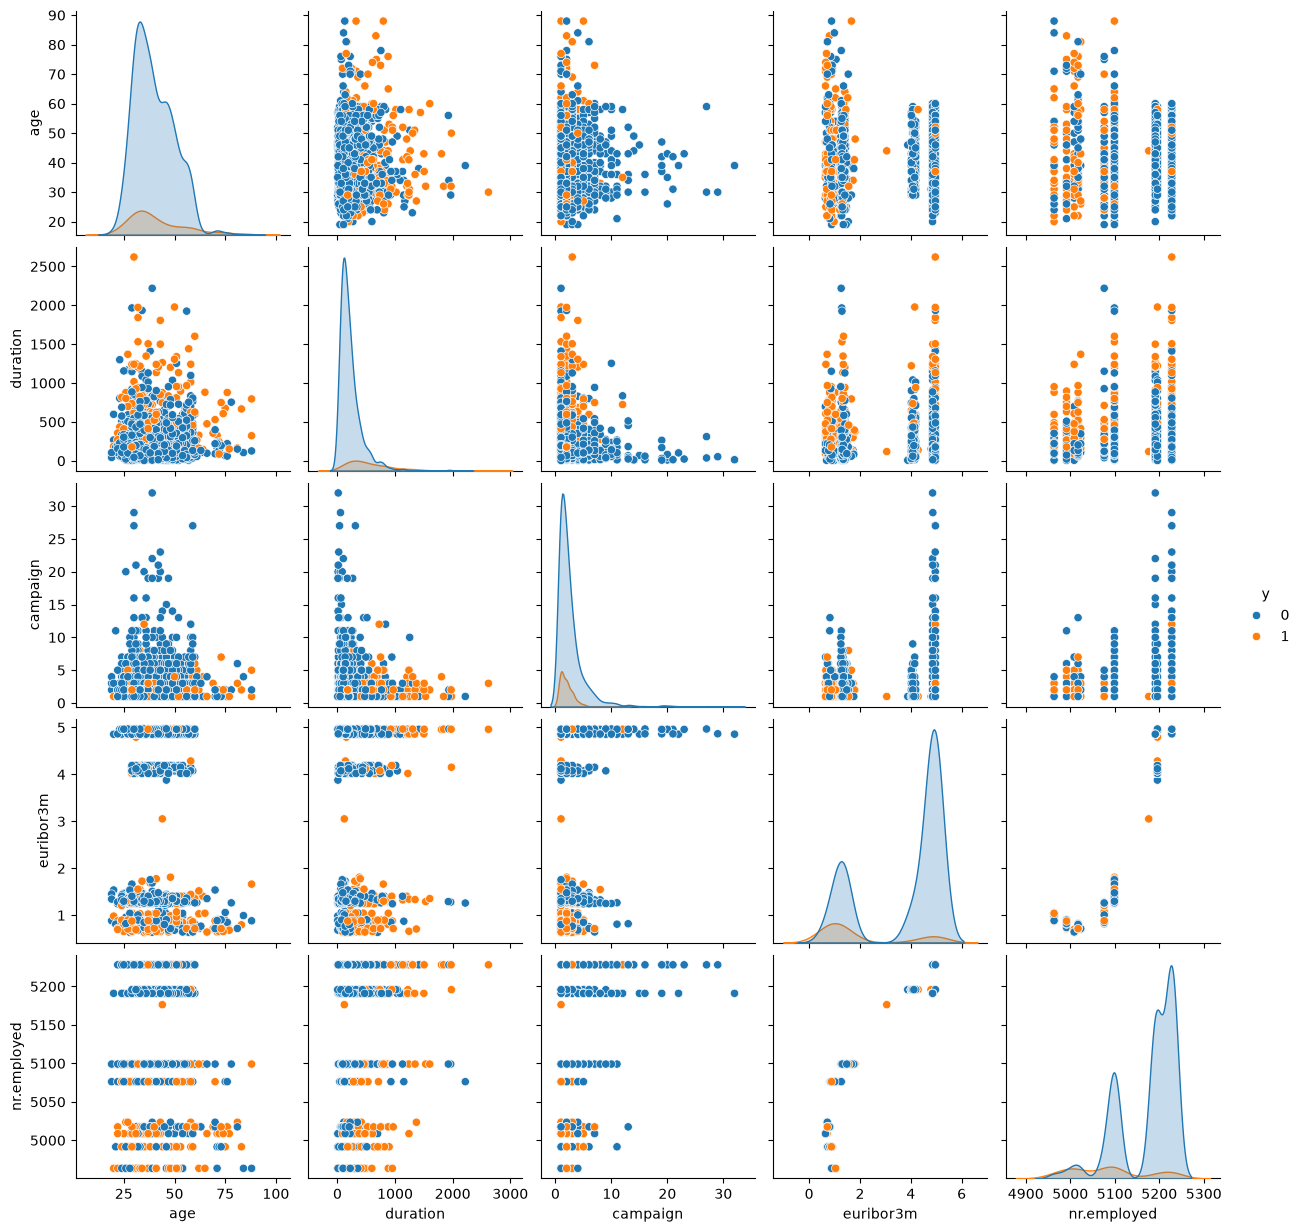

In [19]:
sns.pairplot(df[['age', 'duration', 'campaign', 'euribor3m', 'nr.employed', 'y']].sample(2000, random_state=1), hue='y')
plt.show()

**Insights:** No single numeric column separates yes from no on its own. The clearest pattern is in the economic columns: subscribers (orange) are concentrated where `euribor3m` and `nr.employed` are **low**, meaning the campaign worked better when interest rates and employment were low. `euribor3m` and `nr.employed` also move almost in a straight line together, so they carry the same information.

## 5. Data Preprocessing
### Boxplot

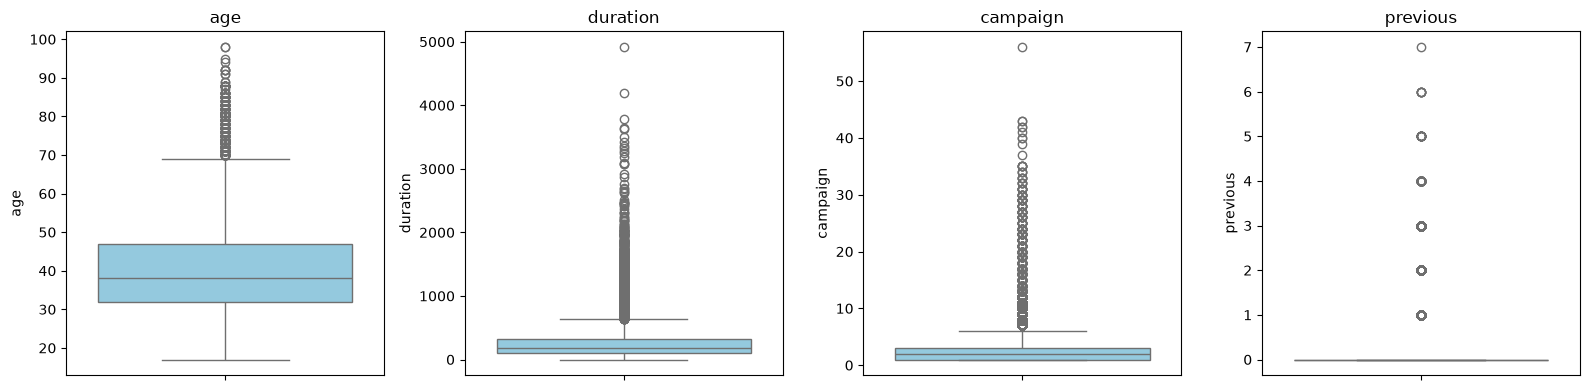

In [20]:
num_cols = ['age', 'duration', 'campaign', 'previous']
fig, axes = plt.subplots(1, 4, figsize=(16,4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color='skyblue')
    ax.set_title(col)
plt.tight_layout()
plt.show()

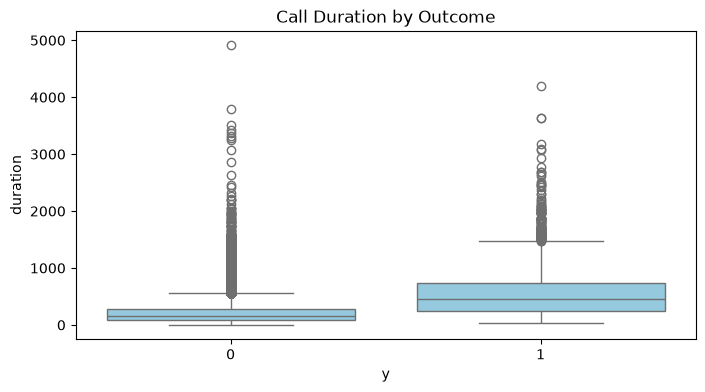

In [21]:
plt.figure(figsize=(8,4))
sns.boxplot(data=df, x='y', y='duration', color='skyblue')
plt.title('Call Duration by Outcome')
plt.show()

In [22]:
# find outliers with the IQR method
for col in ['age', 'duration', 'campaign']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    print(col, '| upper limit:', upper, '| high outliers:', (df[col] > upper).sum(), '| max:', df[col].max())

age | upper limit: 69.5 | high outliers: 468 | max: 98
duration | upper limit: 644.5 | high outliers: 2963 | max: 4918
campaign | upper limit: 6.0 | high outliers: 2406 | max: 56


**Outliers**
- **Age:** 468 customers are above 69.5 years (max 98). These are real retired customers, and they actually subscribe the most, so we **keep them**.
- **Duration:** 2,963 calls are longer than about 11 minutes (max 4,918 seconds = 82 minutes). They are real long calls. This column is not used in the model anyway.
- **Campaign:** 2,406 customers were called more than 6 times (max 56). These are real and show that the bank kept calling customers who were not interested, so we **keep them** and discuss them in Task 3.

None of these outliers are data errors, and tree models are not thrown off by extreme values, so no rows were removed.

### Line Plot

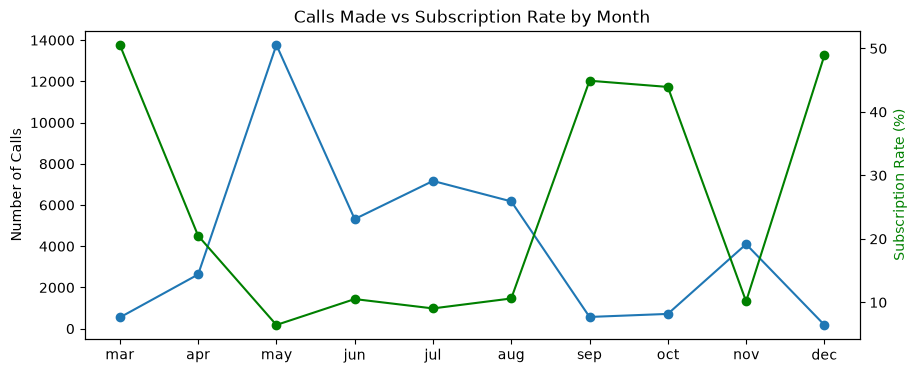

In [23]:
month_order = ['mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
by_month = df.groupby('month').agg(calls=('y', 'count'), rate=('y', 'mean')).reindex(month_order)

fig, ax1 = plt.subplots(figsize=(10,4))
ax1.plot(by_month.index, by_month['calls'], marker='o', label='Number of calls')
ax1.set_ylabel('Number of Calls')
ax2 = ax1.twinx()
ax2.plot(by_month.index, by_month['rate'] * 100, marker='o', color='green', label='Subscription rate')
ax2.set_ylabel('Subscription Rate (%)', color='green')
plt.title('Calls Made vs Subscription Rate by Month')
plt.show()

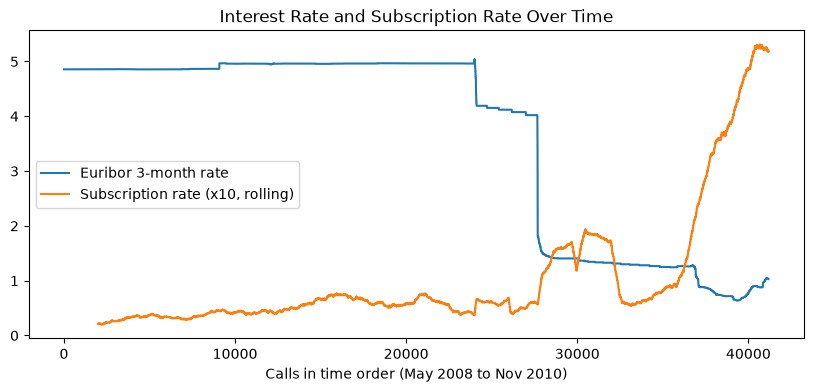

In [24]:
# the data is in time order (May 2008 to Nov 2010), so plot the rate over the rows
df['euribor3m'].reset_index(drop=True).plot(figsize=(10,4), label='Euribor 3-month rate')
(df['y'].reset_index(drop=True).rolling(2000).mean() * 10).plot(label='Subscription rate (x10, rolling)')
plt.title('Interest Rate and Subscription Rate Over Time')
plt.xlabel('Calls in time order (May 2008 to Nov 2010)')
plt.legend()
plt.show()

**Insights:**
- The bank made the **most calls in May (13,767)** but May had the **lowest success rate (6.4%)**. March, September, October and December had very few calls but success rates of **44-50%**.
- The data is in time order. In 2008 the 3-month Euribor rate was around 5% and almost nobody subscribed. After the rate fell below 1.5% (2009-2010, after the financial crisis) the subscription rate rose sharply. So the economic situation had a big effect on the campaign.

### Barplot

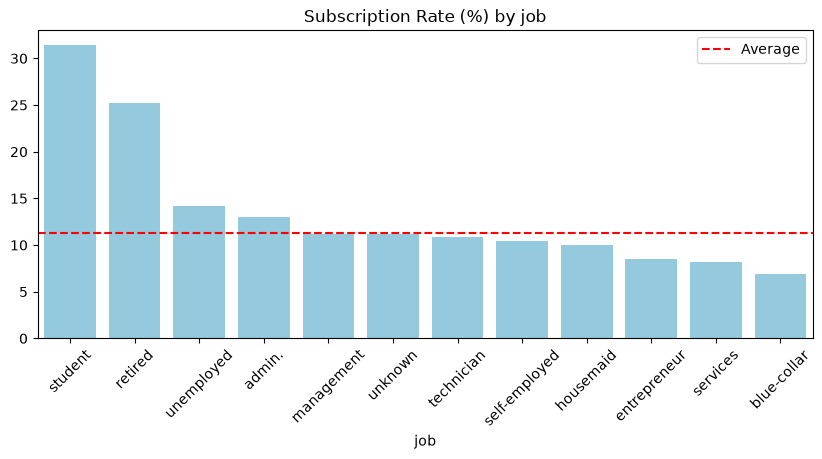

In [25]:
def rate_plot(col, order=None):
    rate = df.groupby(col)['y'].mean().mul(100)
    rate = rate.reindex(order) if order else rate.sort_values(ascending=False)
    plt.figure(figsize=(10,4))
    sns.barplot(x=rate.index.astype(str), y=rate.values, color='skyblue')
    plt.axhline(df['y'].mean() * 100, color='red', linestyle='--', label='Average')
    plt.title('Subscription Rate (%) by ' + col)
    plt.xticks(rotation=45)
    plt.legend()
    plt.show()

rate_plot('job')

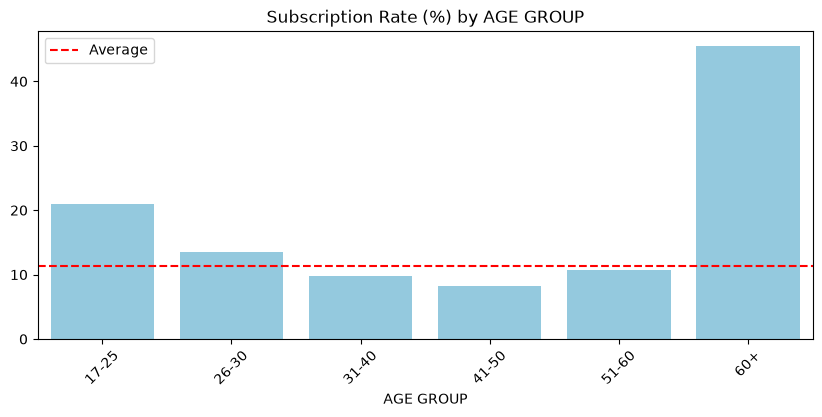

In [26]:
rate_plot('AGE GROUP', ['17-25', '26-30', '31-40', '41-50', '51-60', '60+'])

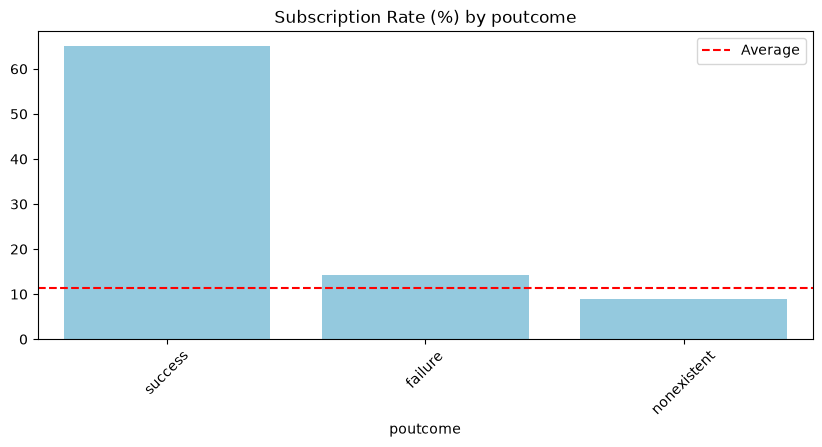

In [27]:
rate_plot('poutcome')

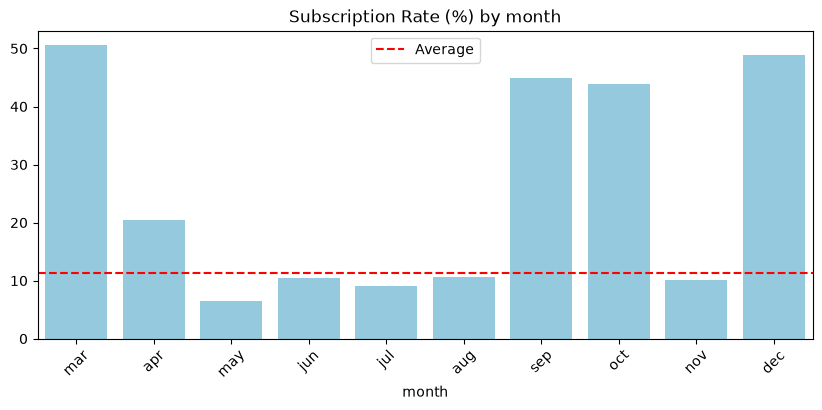

In [28]:
rate_plot('month', month_order)

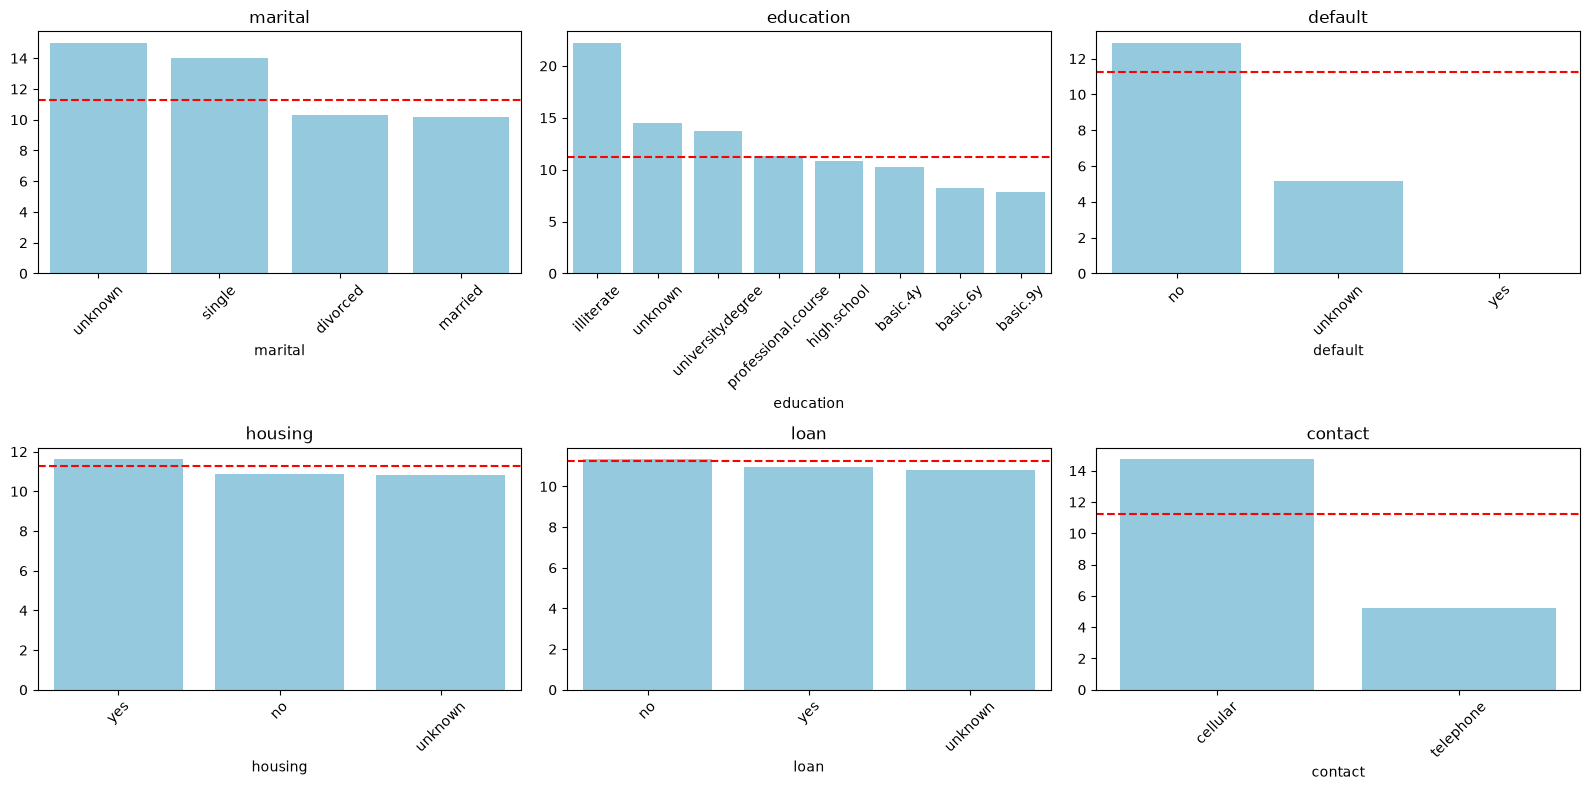

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(16,8))
for ax, col in zip(axes.flat, ['marital', 'education', 'default', 'housing', 'loan', 'contact']):
    rate = df.groupby(col)['y'].mean().mul(100).sort_values(ascending=False)
    sns.barplot(x=rate.index, y=rate.values, ax=ax, color='skyblue')
    ax.axhline(df['y'].mean() * 100, color='red', linestyle='--')
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

**Insights** (red line = average subscription rate of 11.3%)
- **Job:** students (31%) and retired customers (25%) subscribe the most. Blue-collar (6.9%), services (8.1%) and entrepreneurs (8.5%) subscribe the least.
- **Age:** a U-shape. Customers **60+ subscribe 45% of the time** and those **25 or under 21%**, while ages 31-50 are below average.
- **Previous outcome:** customers who said **yes in a previous campaign subscribe 65% of the time**, almost 6 times the average.
- **Contact type:** mobile phone (cellular) 14.7% vs landline (telephone) 5.2%.
- **Default:** customers whose default status is `'unknown'` subscribe much less (5.2%) than those with `'no'` (12.9%).
- **Marital, education, housing loan and personal loan** make only a small difference.

*Note: some of these groups were called mostly in 2009-2010 when interest rates were low and everyone subscribed more. We check this in Task 3 by comparing groups within the same economic period.*

### Encoding
Machine learning models need numbers, so we convert the text columns into numbers with `LabelEncoder`.

In [30]:
from sklearn.preprocessing import LabelEncoder

data = df.drop(columns=['AGE GROUP']).copy()
le = LabelEncoder()
for col in ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']:
    data[col] = le.fit_transform(data[col])
data.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,PREV CONTACTED
0,56,3,1,0,0,0,0,1,6,1,...,1,0,1,1.1,93.994,-36.4,4.857,5191.0,0,0
1,57,7,1,3,1,0,0,1,6,1,...,1,0,1,1.1,93.994,-36.4,4.857,5191.0,0,0
2,37,7,1,3,0,2,0,1,6,1,...,1,0,1,1.1,93.994,-36.4,4.857,5191.0,0,0
3,40,0,1,1,0,0,0,1,6,1,...,1,0,1,1.1,93.994,-36.4,4.857,5191.0,0,0
4,56,7,1,3,0,0,2,1,6,1,...,1,0,1,1.1,93.994,-36.4,4.857,5191.0,0,0


## 6. Feature Selection & Heat Map

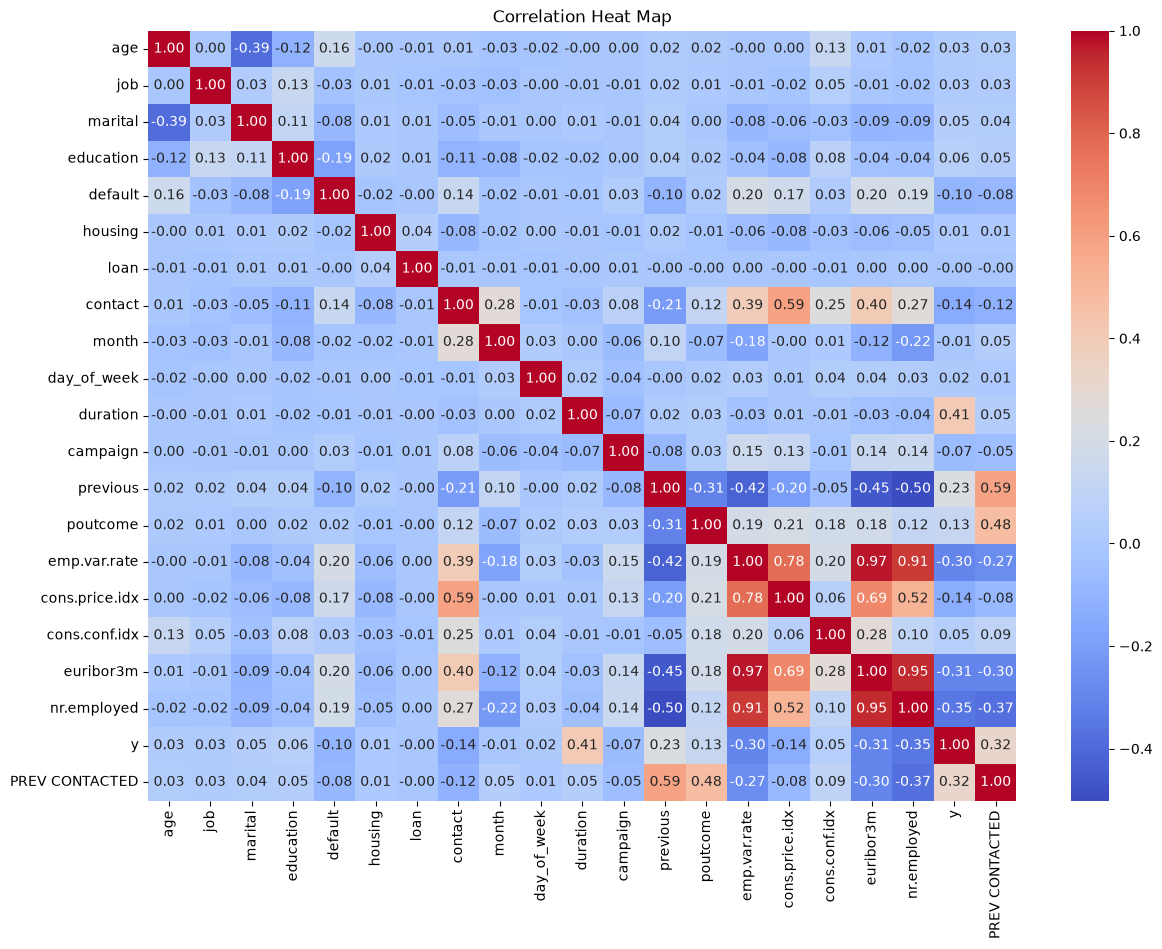

In [31]:
plt.figure(figsize=(14,10))
sns.heatmap(data.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heat Map')
plt.show()

In [32]:
data.corr()['y'].sort_values(ascending=False)

y                 1.000000
duration          0.405297
PREV CONTACTED    0.324910
previous          0.230202
poutcome          0.129810
education         0.057776
cons.conf.idx     0.054802
marital           0.046249
age               0.030381
job               0.025248
day_of_week       0.015970
housing           0.011613
loan             -0.004922
month            -0.006051
campaign         -0.066361
default          -0.099364
cons.price.idx   -0.136134
contact          -0.144774
emp.var.rate     -0.298289
euribor3m        -0.307740
nr.employed      -0.354669
Name: y, dtype: float64

In [33]:
data[['emp.var.rate', 'euribor3m', 'nr.employed', 'cons.price.idx']].corr()

,emp.var.rate,euribor3m,nr.employed,cons.price.idx
emp.var.rate,1.000000,0.972244,0.906949,0.775293
euribor3m,0.972244,1.000000,0.945146,0.688180
nr.employed,0.906949,0.945146,1.000000,0.521945
cons.price.idx,0.775293,0.688180,0.521945,1.000000


**Feature selection**
- `duration` is dropped from the model because of **data leakage**: it is only known after the call ends, so it can't help decide *who to call*. (It has the highest correlation with `y`, 0.41, which is exactly why keeping it would give a fake, too-good score.)
- `emp.var.rate` and `euribor3m` are dropped because they are almost the same as `nr.employed` (correlation 0.91 and 0.95). We keep `nr.employed` because it has the strongest correlation with `y` (-0.35).
- `pdays` was already replaced by the `PREV CONTACTED` flag (correlation 0.32 with `y`).
- The features kept are: `age`, `job`, `marital`, `education`, `default`, `housing`, `loan`, `contact`, `month`, `day_of_week`, `campaign`, `previous`, `poutcome`, `PREV CONTACTED`, `cons.price.idx`, `cons.conf.idx`, `nr.employed`.

# Part 2: Predictive Model

## Which algorithm suits this data best?
We want to predict whether a customer will **subscribe (yes / no)**, so this is a **supervised binary classification** problem.
- Linear Regression is for numbers, not yes/no answers, so it doesn't fit.
- K-Means and PCA are unsupervised, so they don't fit.
- SVM is slow on 41,000 rows and needs a lot of tuning.
- Logistic Regression, Decision Tree, KNN, Random Forest and Gradient Boosting can all do classification, so we try all five and compare them.

**Important:** only about 11% of customers say yes. A model that always says "no" would be 89% accurate and completely useless. So we judge the models on **ROC-AUC**, **recall** (how many real subscribers we find) and **F1**, not on accuracy.

**Expected Best: Gradient Boosting or Random Forest**, because the patterns are non-linear (e.g. the very young and the very old subscribe the most) and tree models handle mixed numeric and category data well.

In [34]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = data.drop(columns=['y', 'duration', 'emp.var.rate', 'euribor3m'])
y = data['y']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# scale the features (needed for Logistic Regression and KNN, does not change tree models)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print(X_train.shape, X_test.shape)
print('Percent yes in train:', round(y_train.mean() * 100, 1), '| in test:', round(y_test.mean() * 100, 1))

(32940, 17) (8236, 17)
Percent yes in train: 11.3 | in test: 11.3


In [35]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# class_weight='balanced' makes the models pay more attention to the small 'yes' class
models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', max_depth=6, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=15),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced', max_depth=10,
                                            min_samples_leaf=5, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
}

results = []
for name, model in models.items():
    if name == 'Gradient Boosting':   # does not have class_weight, so use sample weights instead
        model.fit(X_train_s, y_train, sample_weight=compute_sample_weight('balanced', y_train))
    else:
        model.fit(X_train_s, y_train)
    y_pred = model.predict(X_test_s)
    y_prob = model.predict_proba(X_test_s)[:, 1]
    results.append([name, roc_auc_score(y_train, model.predict_proba(X_train_s)[:, 1]), roc_auc_score(y_test, y_prob),
                    accuracy_score(y_test, y_pred), precision_score(y_test, y_pred), recall_score(y_test, y_pred),
                    f1_score(y_test, y_pred)])

results = pd.DataFrame(results, columns=['Model', 'Train AUC', 'Test AUC', 'Accuracy', 'Precision', 'Recall', 'F1'])
results.sort_values('Test AUC', ascending=False)

,Model,Train AUC,Test AUC,Accuracy,Precision,Recall,F1
3,Random Forest,0.841250,0.810626,0.861583,0.423521,0.632543,0.507347
4,Gradient Boosting,0.810812,0.806843,0.839000,0.375157,0.644397,0.474227
1,Decision Tree,0.792912,0.795223,0.866926,0.436170,0.618534,0.511586
0,Logistic Regression,0.777034,0.787043,0.781326,0.297636,0.691810,0.416207
2,KNN,0.868928,0.760369,0.899223,0.636111,0.246767,0.355590


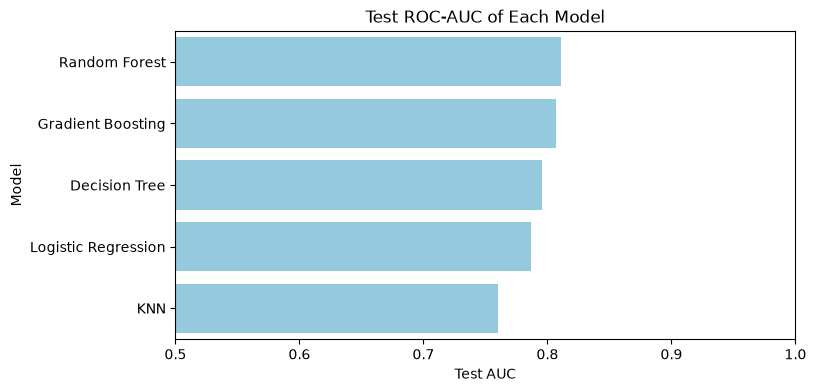

In [36]:
plt.figure(figsize=(8,4))
sns.barplot(data=results.sort_values('Test AUC', ascending=False), x='Test AUC', y='Model', color='skyblue')
plt.title('Test ROC-AUC of Each Model')
plt.xlim(0.5, 1)
plt.show()

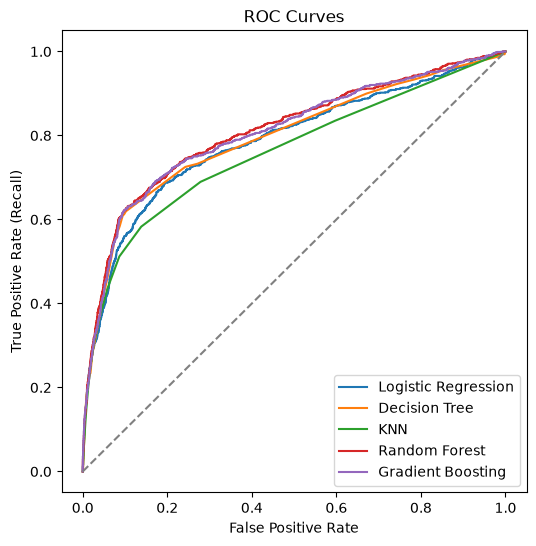

In [37]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(6,6))
for name, model in models.items():
    fpr, tpr, _ = roc_curve(y_test, model.predict_proba(X_test_s)[:, 1])
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], color='grey', linestyle='--')
plt.title('ROC Curves')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.legend()
plt.show()

### Cross-validation check
The top models are very close on the single test split, so we check them with **5-fold cross-validation**: the data is split 5 different ways and each model is trained and tested 5 times. This shows whether a small difference is real or just luck of one split.

In [38]:
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_score
from sklearn.pipeline import make_pipeline

cv_models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=1000)),
    'Decision Tree': DecisionTreeClassifier(class_weight='balanced', max_depth=6, random_state=42),
    'KNN': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced', max_depth=10,
                                            min_samples_leaf=5, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'Gradient Boosting (tuned)': GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                                                            subsample=0.8, random_state=42),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = []
for name, model in cv_models.items():
    scores = cross_validate(model, X, y, cv=cv, scoring=['roc_auc', 'average_precision'])
    cv_results.append([name, scores['test_roc_auc'].mean(), scores['test_roc_auc'].std(), scores['test_average_precision'].mean()])

cv_results = pd.DataFrame(cv_results, columns=['Model', 'CV AUC (mean)', 'CV AUC (std)', 'CV PR-AUC'])
cv_results.sort_values('CV AUC (mean)', ascending=False).round(3)

,Model,CV AUC (mean),CV AUC (std),CV PR-AUC
3,Random Forest,0.799,0.015,0.470
5,Gradient Boosting (tuned),0.798,0.014,0.464
4,Gradient Boosting,0.797,0.014,0.468
1,Decision Tree,0.784,0.017,0.426
0,Logistic Regression,0.778,0.011,0.439
2,KNN,0.755,0.011,0.395


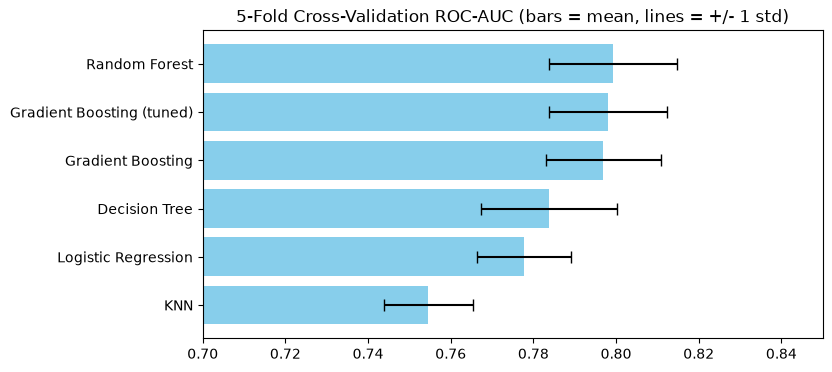

In [39]:
cv_sorted = cv_results.sort_values('CV AUC (mean)')
plt.figure(figsize=(8,4))
plt.barh(cv_sorted['Model'], cv_sorted['CV AUC (mean)'], xerr=cv_sorted['CV AUC (std)'], color='skyblue', capsize=4)
plt.title('5-Fold Cross-Validation ROC-AUC (bars = mean, lines = +/- 1 std)')
plt.xlim(0.7, 0.85)
plt.show()

**Cross-validation result:** Random Forest (0.799), tuned Gradient Boosting (0.798) and default Gradient Boosting (0.797) are **statistically tied**. The difference between them (about 0.002) is much smaller than how much each score moves from one split to another (std about 0.015), so a different random split could put Gradient Boosting first. Tuning Gradient Boosting barely helped (0.797 to 0.798), which suggests the data itself limits the score to about 0.80, not the choice of algorithm. Decision Tree, Logistic Regression and KNN are clearly behind in every fold.

The cross-validated AUC (about 0.80) is slightly lower than the single test split (0.81), so **0.80 is the more honest estimate** of how the model will perform on new customers.

## Hyperparameter Tuning
So far the models used hand-picked settings. Here we search for better settings in a structured way:
1. **GridSearchCV** on Random Forest: try every combination of `n_estimators` and `max_depth`.
2. **RandomizedSearchCV** on Random Forest: try 15 random combinations from a wider range of settings.
3. **RandomizedSearchCV** on **HistGradientBoosting**, a faster version of Gradient Boosting. Boosting builds trees one after another, each fixing the mistakes of the previous ones, unlike Random Forest which builds independent trees and averages them.

All searches use **only the training data** with 3-fold cross-validation and are scored on ROC-AUC. The test set is kept aside for the final comparison.

*Note: this section takes several minutes to run.*

In [40]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import HistGradientBoostingClassifier
from scipy.stats import randint, loguniform

cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# 1. Grid search: n_estimators x max_depth
rf_grid = GridSearchCV(RandomForestClassifier(class_weight='balanced', min_samples_leaf=5, random_state=42, n_jobs=-1),
                       param_grid={'n_estimators': [100, 300, 500], 'max_depth': [6, 8, 10, 12, 15, None]},
                       scoring='roc_auc', cv=cv3)
rf_grid.fit(X_train, y_train)
print('Best settings :', rf_grid.best_params_)
print('Best CV AUC   :', round(rf_grid.best_score_, 4))

Best settings : {'max_depth': 10, 'n_estimators': 100}
Best CV AUC   : 0.7951


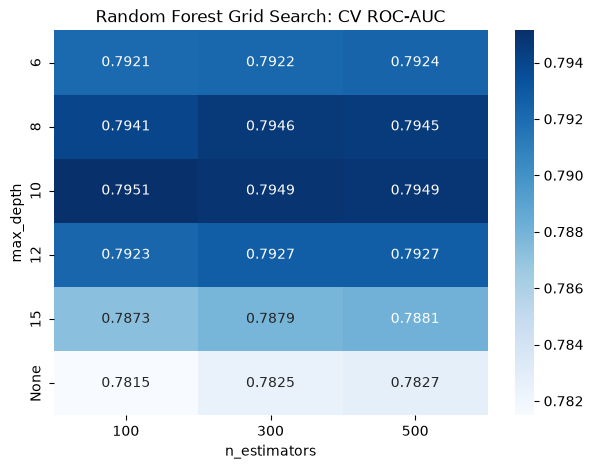

In [41]:
grid_table = pd.DataFrame(rf_grid.cv_results_)
grid_table['max_depth'] = grid_table['param_max_depth'].apply(lambda d: 'None' if pd.isna(d) else str(int(d)))   # so that None is shown too
grid_table = grid_table.pivot_table(index='max_depth', columns='param_n_estimators', values='mean_test_score')
grid_table = grid_table.reindex(['6', '8', '10', '12', '15', 'None'])

plt.figure(figsize=(7,5))
sns.heatmap(grid_table, annot=True, fmt='.4f', cmap='Blues')
plt.title('Random Forest Grid Search: CV ROC-AUC')
plt.xlabel('n_estimators')
plt.show()

In [42]:
# 2. Randomized search on Random Forest (wider range of settings)
rf_random = RandomizedSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1),
                               param_distributions={'n_estimators': randint(200, 600),
                                                    'max_depth': randint(6, 20),
                                                    'min_samples_leaf': randint(1, 30),
                                                    'max_features': ['sqrt', 'log2', 0.5],
                                                    'class_weight': ['balanced', 'balanced_subsample', None]},
                               n_iter=15, scoring='roc_auc', cv=cv3, random_state=42)
rf_random.fit(X_train, y_train)
print('Best settings :', rf_random.best_params_)
print('Best CV AUC   :', round(rf_random.best_score_, 4))

Best settings : {'class_weight': 'balanced_subsample', 'max_depth': 10, 'max_features': 'log2', 'min_samples_leaf': 20, 'n_estimators': 291}
Best CV AUC   : 0.7944


In [43]:
# 3. Randomized search on HistGradientBoosting
hgb_random = RandomizedSearchCV(HistGradientBoostingClassifier(random_state=42, early_stopping=False),
                                param_distributions={'learning_rate': loguniform(0.01, 0.2),
                                                     'max_iter': randint(100, 600),
                                                     'max_depth': [3, 4, 5, 6, 8, None],
                                                     'max_leaf_nodes': randint(15, 63),
                                                     'min_samples_leaf': randint(20, 200),
                                                     'l2_regularization': loguniform(0.001, 10),
                                                     'class_weight': [None, 'balanced']},
                                n_iter=30, scoring='roc_auc', cv=cv3, random_state=42)
hgb_random.fit(X_train, y_train)
print('Best settings :', hgb_random.best_params_)
print('Best CV AUC   :', round(hgb_random.best_score_, 4))

Best settings : {'class_weight': None, 'l2_regularization': np.float64(0.004936948694960458), 'learning_rate': np.float64(0.032268708256236636), 'max_depth': 4, 'max_iter': 459, 'max_leaf_nodes': 18, 'min_samples_leaf': 21}
Best CV AUC   : 0.7935


## Ensembles Beyond Bagging
Random Forest is a **bagging** ensemble (many trees on random samples, averaged). We also try two ways of combining *different kinds* of models:
- **Soft Voting:** average the predicted probabilities of the tuned Random Forest, the tuned HistGradientBoosting and Logistic Regression.
- **Stacking:** the same base models (plus Extra Trees) make predictions, and a Logistic Regression **meta-model** learns how much to trust each one.

**Important:** the rows in this file are in **time order** (2008 to 2010). Stacking's default `cv=5` does not shuffle, so the meta-model would learn from predictions made across different economic periods and give very wrong weights (we saw an AUC of about 0.27 when testing this). So we pass a **shuffled** `StratifiedKFold`.

In [44]:
from sklearn.ensemble import VotingClassifier, StackingClassifier, ExtraTreesClassifier

lr_pipe = make_pipeline(StandardScaler(), LogisticRegression(class_weight='balanced', max_iter=1000))

voting = VotingClassifier([('rf', rf_random.best_estimator_), ('hgb', hgb_random.best_estimator_), ('lr', lr_pipe)],
                          voting='soft')
voting.fit(X_train, y_train)

stacking = StackingClassifier([('rf', rf_random.best_estimator_), ('hgb', hgb_random.best_estimator_),
                               ('et', ExtraTreesClassifier(n_estimators=400, max_depth=12, min_samples_leaf=5,
                                                           class_weight='balanced', random_state=42, n_jobs=-1)),
                               ('lr', lr_pipe)],
                              final_estimator=LogisticRegression(max_iter=1000),
                              cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42), stack_method='predict_proba')
stacking.fit(X_train, y_train)
print('Stacking weights (rf, hgb, et, lr):', stacking.final_estimator_.coef_.round(2))

Stacking weights (rf, hgb, et, lr): [[2.83 2.15 0.78 0.06]]


### Comparing the tuned models and ensembles
We compare them on the **test set** and with **5-fold cross-validation** on the full data. Besides ROC-AUC we show **PR-AUC** (how well the "yes" customers are found) and the share of all subscribers reached by calling only the **top 20%** of customers ranked by the model, which is how the bank would actually use it.

In [45]:
from sklearn.metrics import average_precision_score

def top20_capture(y_true, prob):
    order = np.argsort(-prob)
    top = np.asarray(y_true)[order][:int(len(prob) * 0.2)]
    return top.sum() / np.sum(y_true)

# the hand-picked models were trained on scaled data, the tuned ones on the original data
final_models = {
    'Random Forest (hand-picked)': (cv_models['Random Forest'], models['Random Forest'], X_test_s),
    'Random Forest (grid search)': (rf_grid.best_estimator_, rf_grid.best_estimator_, X_test),
    'Random Forest (random search)': (rf_random.best_estimator_, rf_random.best_estimator_, X_test),
    'HistGradientBoosting (random search)': (hgb_random.best_estimator_, hgb_random.best_estimator_, X_test),
    'Soft Voting': (voting, voting, X_test),
    'Stacking': (stacking, stacking, X_test),
}
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
tuned = []
for name, (unfitted, fitted, X_eval) in final_models.items():
    prob = fitted.predict_proba(X_eval)[:, 1]
    cv_auc = cross_val_score(unfitted, X, y, cv=cv5, scoring='roc_auc')
    tuned.append([name, roc_auc_score(y_test, prob), average_precision_score(y_test, prob),
                  top20_capture(y_test, prob) * 100, cv_auc.mean(), cv_auc.std()])

tuned = pd.DataFrame(tuned, columns=['Model', 'Test AUC', 'Test PR-AUC', '% subscribers in top 20%', 'CV AUC (mean)', 'CV AUC (std)'])
tuned.sort_values('CV AUC (mean)', ascending=False).round(4)

,Model,Test AUC,Test PR-AUC,% subscribers in top 20%,CV AUC (mean),CV AUC (std)
0,Random Forest (hand-picked),0.8106,0.4828,65.7328,0.7993,0.0154
5,Stacking,0.8093,0.4842,65.5172,0.7991,0.0154
2,Random Forest (random search),0.8101,0.4860,65.7328,0.7991,0.0153
1,Random Forest (grid search),0.8098,0.4805,66.0560,0.7989,0.0155
3,HistGradientBoosting (random search),0.8059,0.4786,65.6250,0.7988,0.0143
4,Soft Voting,0.8052,0.4777,65.3017,0.7958,0.0136


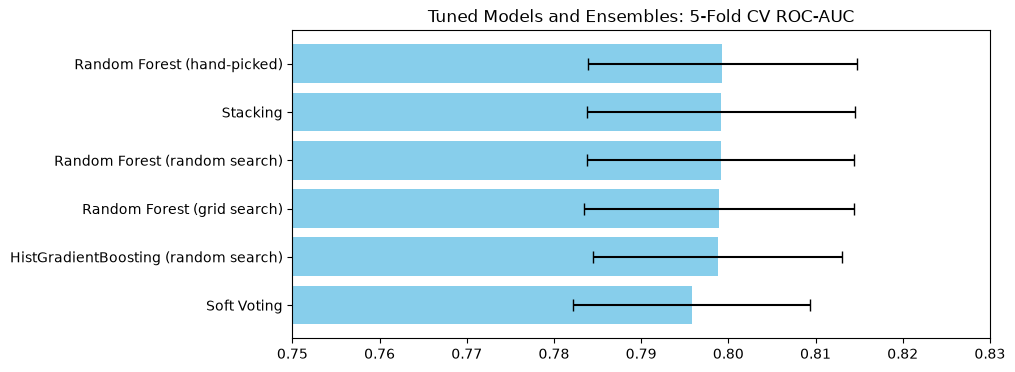

In [46]:
tuned_sorted = tuned.sort_values('CV AUC (mean)')
plt.figure(figsize=(9,4))
plt.barh(tuned_sorted['Model'], tuned_sorted['CV AUC (mean)'], xerr=tuned_sorted['CV AUC (std)'], color='skyblue', capsize=4)
plt.title('Tuned Models and Ensembles: 5-Fold CV ROC-AUC')
plt.xlim(0.75, 0.83)
plt.show()

**Tuning result: the extra effort did not improve the model, and that is a useful finding.**

**What the grid search showed (`n_estimators` x `max_depth`):**
- **`max_depth` matters, `n_estimators` does not.** The best depth is **10** (CV AUC 0.795). Shallower trees (depth 6: 0.792) are too simple, and deeper trees get steadily worse (depth 15: 0.788, unlimited depth: 0.782) because they start **memorising the training data** (overfitting).
- Going from 100 to 500 trees changes the score by less than 0.001, so 100-300 trees is enough. More trees only make training slower.
- The best settings (depth 10) are the **same as the hand-picked settings** we used, so the search confirms our original choice.

**What the randomized searches found:**
- **Random Forest** (15 combinations, also trying `min_samples_leaf`, `max_features` and `class_weight`): best was depth 10, `min_samples_leaf` 20, `max_features='log2'`, CV AUC 0.794. No better than the grid search.
- **HistGradientBoosting** (30 combinations): best was a slow learning rate (0.03), about 460 small trees (depth 4), CV AUC 0.794. Same level as Random Forest.

**Ensembles beyond bagging:**
- **Stacking** gave most weight to Random Forest (2.83) and HistGradientBoosting (2.15), less to Extra Trees (0.78) and almost none to Logistic Regression (0.06). Its CV AUC (0.799) **ties** the hand-picked Random Forest.
- **Soft Voting** was slightly **worse** (0.796), because averaging in the weaker Logistic Regression pulls the score down.

**Final comparison:** all six models are between **0.796 and 0.799** CV AUC, and all reach about **65-66% of subscribers in the top 20%**. The differences (at most 0.0035) are much smaller than the normal variation between folds (std about 0.015).

**Why tuning didn't help:** the limit is the **information in the data**, not the algorithm. The strongest predictor (call duration) can't be used, and most of the remaining signal comes from a few economic indicators and the previous-campaign columns, which every good tree model already captures. To improve further the bank would need **new information** (e.g. account balance, income, or product holdings), not a more complex model.

**Decision:** keep the **hand-picked Random Forest** (`max_depth=10`, 300 trees). It ties for best, its settings are confirmed by the grid search, and it is much simpler to explain, maintain and retrain than a stacking ensemble of four models.

              precision    recall  f1-score   support

           0       0.95      0.89      0.92      7308
           1       0.42      0.63      0.51       928

    accuracy                           0.86      8236
   macro avg       0.69      0.76      0.71      8236
weighted avg       0.89      0.86      0.87      8236



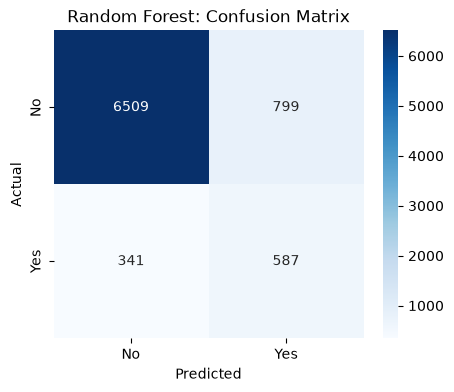

In [47]:
from sklearn.metrics import confusion_matrix, classification_report

best = models['Random Forest']
y_pred = best.predict(X_test_s)
print(classification_report(y_test, y_pred))

plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
plt.title('Random Forest: Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

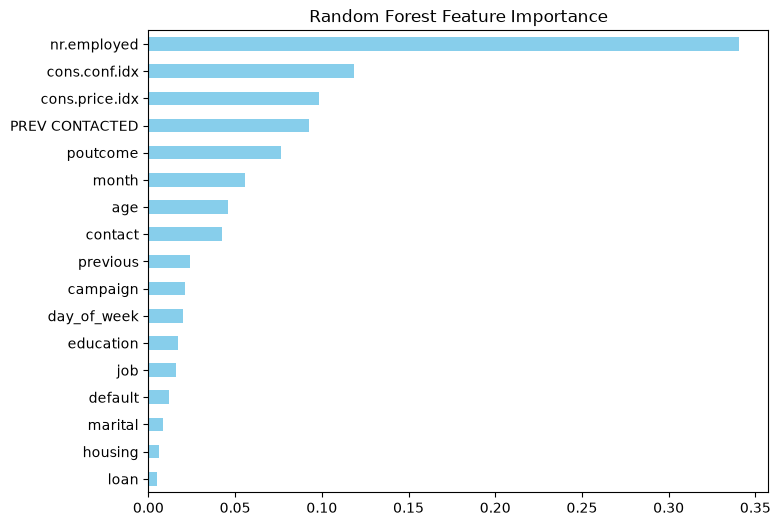

In [48]:
importance = pd.Series(best.feature_importances_, index=X.columns).sort_values()
importance.plot(kind='barh', color='skyblue', figsize=(8,6))
plt.title('Random Forest Feature Importance')
plt.show()

In [49]:
# if the bank calls only the customers the model ranks highest, how many subscribers does it reach?
test = pd.DataFrame({'actual': y_test.values, 'prob': best.predict_proba(X_test_s)[:, 1]}).sort_values('prob', ascending=False)
for pct in [10, 20, 30, 50]:
    top = test.head(int(len(test) * pct / 100))
    print(f'Call top {pct}% of customers -> reach {top.actual.sum() / test.actual.sum() * 100:.1f}% of all subscribers '
          f'(success rate {top.actual.mean() * 100:.1f}% vs {test.actual.mean() * 100:.1f}% when calling everyone)')

Call top 10% of customers -> reach 46.7% of all subscribers (success rate 52.6% vs 11.3% when calling everyone)
Call top 20% of customers -> reach 65.7% of all subscribers (success rate 37.0% vs 11.3% when calling everyone)
Call top 30% of customers -> reach 74.6% of all subscribers (success rate 28.0% vs 11.3% when calling everyone)
Call top 50% of customers -> reach 83.3% of all subscribers (success rate 18.8% vs 11.3% when calling everyone)


**Result:** **Random Forest** and **Gradient Boosting** are tied for the best model (cross-validated ROC-AUC about **0.80**). We choose **Random Forest** because it scored highest by a very small margin, the grid search confirmed its settings (`max_depth=10`), and it is easy to explain. Hyperparameter tuning (GridSearchCV, RandomizedSearchCV) and more advanced ensembles (soft voting, stacking) were also tried, but none of them did better (all between 0.796 and 0.799 CV AUC). On the test set it has a **ROC-AUC of 0.81**. It finds **63% of the real subscribers** (recall), and when it says "yes" it is right 42% of the time, almost 4 times better than the 11% success rate of calling everyone.

The feature importance chart shows that the **economic situation (`nr.employed`, consumer confidence and price index)** matters most, followed by **whether the customer was contacted before and what happened** (`PREV CONTACTED`, `poutcome`), the **month**, **age** and **contact type**. Personal details like marital status, housing loan and personal loan matter very little.

**Business value:** If the bank calls only the **top 20%** of customers ranked by the model, it reaches **66% of all subscribers** with a success rate of **37%** instead of 11%. That means about 80% fewer calls for two-thirds of the sales.

# Part 3: Suggestions for the Bank Marketing Team

## Which customers should the bank focus on?

In [50]:
# subscription rate for the most promising customer groups
groups = {
    'All customers': df,
    'Previous campaign = success': df[df['poutcome'] == 'success'],
    'Students': df[df['job'] == 'student'],
    'Retired': df[df['job'] == 'retired'],
    'Age 60+': df[df['age'] > 60],
    'Age 25 or under': df[df['age'] <= 25],
    'Contacted by mobile (cellular)': df[df['contact'] == 'cellular'],
    'Contacted by landline (telephone)': df[df['contact'] == 'telephone'],
    'Blue-collar': df[df['job'] == 'blue-collar'],
    'Called in May': df[df['month'] == 'may'],
    'Called in Mar / Sep / Oct / Dec': df[df['month'].isin(['mar', 'sep', 'oct', 'dec'])],
}
segment = pd.DataFrame({name: [len(g), g['y'].mean() * 100] for name, g in groups.items()}, index=['Customers', 'Subscription %']).T
segment['Customers'] = segment['Customers'].astype(int)
segment.sort_values('Subscription %', ascending=False).round(1)

,Customers,Subscription %
Previous campaign = success,1373,65.1
Called in Mar / Sep / Oct / Dec,2015,46.5
Age 60+,909,45.5
Students,875,31.4
Retired,1718,25.3
Age 25 or under,1665,21.0
Contacted by mobile (cellular),26135,14.7
All customers,41176,11.3
Blue-collar,9253,6.9
Called in May,13767,6.4


In [51]:
# check: the economy changed a lot during the campaign, and some groups (like customers over 60) were almost only
# called in 2009-2010 when interest rates were low and everyone subscribed more.
# so compare each group with the average customer in the SAME economic period
df['RATE PERIOD'] = np.where(df['euribor3m'] < 2, 'low rates (below 2%)', 'high rates (above 2%)')
fair = pd.DataFrame({name: df.loc[g.index].groupby('RATE PERIOD')['y'].mean() * 100 for name, g in groups.items()}).T
fair['% called in low-rate period'] = [(g['euribor3m'] < 2).mean() * 100 for g in groups.values()]
fair.sort_values('low rates (below 2%)', ascending=False).round(1)

RATE PERIOD,high rates (above 2%),low rates (below 2%),% called in low-rate period
Previous campaign = success,8.6,66.6,97.5
Called in Mar / Sep / Oct / Dec,55.8,46.1,96.2
Age 60+,0.0,45.6,99.9
Retired,5.9,41.9,53.7
Students,7.3,38.3,77.9
Age 25 or under,5.7,33.0,55.8
Contacted by mobile (cellular),5.7,25.1,46.5
All customers,4.8,24.5,32.8
Contacted by landline (telephone),3.9,18.7,8.8
Blue-collar,4.7,12.0,30.1


In [52]:
# number of calls, split by economic period
df.groupby(['RATE PERIOD', pd.cut(df['campaign'], bins=[0, 3, 5, 10, 60], labels=['1-3', '4-5', '6-10', '11+'])])['y'].mean().mul(100).round(1).unstack()

campaign,1-3,4-5,6-10,11+
RATE PERIOD,,,,
high rates (above 2%),4.9,4.7,5.0,2.9
low rates (below 2%),25.8,18.8,10.8,5.8


In [53]:
# how many calls are worth making?
df['CALLS'] = pd.cut(df['campaign'], bins=[0, 1, 2, 3, 5, 10, 60], labels=['1', '2', '3', '4-5', '6-10', '11+'])
calls = df.groupby('CALLS').agg(customers=('y', 'count'), subscription_pct=('y', 'mean'))
calls['subscription_pct'] = (calls['subscription_pct'] * 100).round(1)
calls

,customers,subscription_pct
CALLS,,
1,17634,13.0
2,10568,11.5
3,5340,10.7
4-5,4249,8.7
6-10,2516,6.3
11+,869,3.1


In [54]:
# share of all calls that went to customers who had already been called more than 5 times
print('Percent of customers called more than 5 times:', round((df['campaign'] > 5).mean() * 100, 1))
print('Percent of all subscribers who needed more than 5 calls:', round(df[df['y'] == 1]['campaign'].gt(5).mean() * 100, 1))

Percent of customers called more than 5 times: 8.2
Percent of all subscribers who needed more than 5 calls: 4.0


In [55]:
# economic conditions: the bank does better when interest rates (euribor) are low
df['EURIBOR LEVEL'] = pd.cut(df['euribor3m'], bins=[0, 2, 6], labels=['low (below 2%)', 'high (above 2%)'])
df.groupby('EURIBOR LEVEL').agg(customers=('y', 'count'), subscription_pct=('y', 'mean')).assign(subscription_pct=lambda t: (t.subscription_pct * 100).round(1))

,customers,subscription_pct
EURIBOR LEVEL,,
low (below 2%),13494,24.5
high (above 2%),27682,4.8


In [56]:
# talk time: longer calls are linked with a yes (but duration is only known after the call)
df['CALL LENGTH'] = pd.cut(df['duration'], bins=[-1, 120, 300, 600, 5000], labels=['< 2 min', '2-5 min', '5-10 min', '10+ min'])
df.groupby('CALL LENGTH').agg(customers=('y', 'count'), subscription_pct=('y', 'mean')).assign(subscription_pct=lambda t: (t.subscription_pct * 100).round(1))

,customers,subscription_pct
CALL LENGTH,,
< 2 min,12912,1.3
2-5 min,17062,7.9
5-10 min,7738,18.6
10+ min,3464,48.6


## Suggestions for the Marketing Team

**A note on fair comparison:** the economy changed a lot during the campaign. In 2008 interest rates were high and only **4.8%** of customers subscribed; in 2009-2010 rates were low and **24.5%** subscribed. Some groups were called almost only in the good period (99.9% of customers over 60, 97.5% of past subscribers), so their overall rates look better than they really are. The suggestions below are checked **inside the same economic period**, comparing each group with the average customer of that period.

### 1. Focus on the customers most likely to say yes
| Customer group | Overall rate | Low-rate period (average 24.5%) | High-rate period (average 4.8%) |
|---|---|---|---|
| Said yes in a previous campaign | 65.1% | **66.6%** | 8.6% (only about 30 customers) |
| Age over 60 | 45.5% | **45.6%** | (almost none called) |
| Retired | 25.3% | **41.9%** | 5.9% |
| Students | 31.4% | **38.3%** | 7.3% |
| Age 25 or under | 21.0% | **33.0%** | 5.7% |
| Blue-collar | 6.9% | 12.0% | 4.7% |

* **Past subscribers** are the best customers by far: in the same period they subscribe almost **3 times** more than the average customer. Keep a list of everyone who said yes before and call them first in every new campaign.
* **Older and retired customers** subscribe **1.7-1.9 times** more than average. They have savings and want a safe, fixed return, which is exactly what a term deposit offers.
* **Students and young customers** also respond well (**1.3-1.6 times** the average). Smaller deposit amounts or a student savings plan could work for them.
* **Blue-collar** customers respond the least in both periods. Don't remove them, but don't make them the main target.

---

### 2. Use the model to choose who to call
* Rank customers by the Random Forest's predicted probability and call from the top of the list.
* Calling the **top 20%** reaches **66% of subscribers** at a **37% success rate** (vs 11% when calling everyone).
* The time saved can be spent on longer, better-quality calls with the right customers.

---

### 3. Stop calling the same customer too many times
* Overall, the success rate falls with each call: **13% on the 1st call, 8.7% at 4-5 calls, 6.3% at 6-10 calls and 3.1% after 10 calls**.
* In the low-rate period (when most sales happened) it drops from **25.8% for 1-3 calls to 10.8% for 6-10 calls**.
* Only **4% of all subscribers needed more than 5 calls**, but **8.2% of customers** were called more than 5 times.
* **Suggestion:** set a limit of about **3-5 calls per customer** per campaign. More calls cost money and can annoy customers.

---

### 4. Call on mobile phones
* Overall, mobile (cellular) calls succeed **14.7%** of the time vs **5.2%** on landlines. Part of this gap is because 91% of landline calls were made in the bad 2008 period.
* In the same period, mobile is still better: **25.1% vs 18.7%** (low rates) and **5.7% vs 3.9%** (high rates), about **1.4 times** better. Ask customers for a mobile number and use it first.

---

### 5. Plan around the timing and the economy
* **May had the most calls (13,767) but the lowest success rate (6.4%)**, and it is below average in both periods (10.8% vs 24.5%, and 3.1% vs 4.8%). The bank made too many calls in May. March, September, October and December had few calls but **44-50% success**. Spread calls more evenly through the year instead of making most of them in early summer.
* Customers subscribe much more when interest rates are **low**: **24.5%** when the Euribor rate was below 2% vs **4.8%** when it was above 2%. When rates are low, people look for safe products, so the bank should run bigger campaigns at those times and smaller, more targeted ones when rates are high.

---

### 6. Keep the conversation going
* Calls that lasted **more than 10 minutes ended in a yes 49% of the time**, while calls under 2 minutes almost never did (1.3%). Train staff to explain the product clearly and answer questions instead of keeping calls short. (Duration is a result of a good conversation, not something we can choose in advance, so it is not used in the model.)

### Summary
The bank should **call past subscribers, older/retired customers and students first**, **use mobile numbers**, **limit each customer to about 3-5 calls**, **avoid putting most calls into May**, **run bigger campaigns when interest rates are low** and **use the model's ranking** to decide who to call. This should give a much higher success rate with far fewer calls.

# Model Comparison Report

**Goal:** Predict whether a customer will **subscribe to a term deposit (yes / no)** from their personal details, past campaign history and the economic situation at the time of the call. The data has 41,176 rows (after removing duplicates), split 80% for training and 20% for testing, keeping the same 11.3% "yes" rate in both.

| Model | Train AUC | Test AUC | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|---|---|
| **Random Forest** | 0.841 | **0.811** | 0.862 | 0.424 | 0.633 | 0.507 |
| Gradient Boosting | 0.811 | 0.807 | 0.839 | 0.375 | 0.644 | 0.474 |
| Decision Tree | 0.793 | 0.795 | 0.867 | 0.436 | 0.619 | **0.512** |
| Logistic Regression | 0.777 | 0.787 | 0.781 | 0.298 | **0.692** | 0.416 |
| KNN | 0.869 | 0.760 | **0.899** | **0.636** | 0.247 | 0.356 |

*ROC-AUC = how well the model ranks a yes above a no (1.0 is perfect, 0.5 is guessing). Precision = of the customers the model says "yes" to, how many really subscribed. Recall = of all real subscribers, how many the model found. F1 = balance of precision and recall.*

**5-fold cross-validation (more reliable than one split)**

| Model | CV AUC (mean) | CV AUC (std) | CV PR-AUC |
|---|---|---|---|
| **Random Forest** | **0.799** | 0.015 | **0.470** |
| Gradient Boosting (tuned) | 0.798 | 0.014 | 0.464 |
| Gradient Boosting | 0.797 | 0.014 | 0.468 |
| Decision Tree | 0.784 | 0.017 | 0.426 |
| Logistic Regression | 0.778 | 0.011 | 0.439 |
| KNN | 0.755 | 0.011 | 0.395 |

*PR-AUC = how well the model finds the "yes" customers (the small class); the average if you guess is 0.11.*

**Hyperparameter Tuning & Advanced Ensembles**

| Model | How it was built | Test AUC | Test PR-AUC | % subscribers in top 20% | CV AUC (mean) |
|---|---|---|---|---|---|
| **Random Forest (hand-picked)** | depth 10, 300 trees | **0.811** | 0.483 | 65.7% | **0.799** |
| Stacking | RF + HGB + Extra Trees + LR, LR meta-model | 0.809 | 0.484 | 65.5% | 0.799 |
| Random Forest (random search) | 15 random combinations | 0.810 | **0.486** | 65.7% | 0.799 |
| Random Forest (grid search) | `n_estimators` x `max_depth`, 18 combinations | 0.810 | 0.481 | **66.1%** | 0.799 |
| HistGradientBoosting (random search) | 30 random combinations | 0.806 | 0.479 | 65.6% | 0.799 |
| Soft Voting | average of RF + HGB + LR | 0.805 | 0.478 | 65.3% | 0.796 |

The grid search picked `max_depth=10`, the same as our hand-picked value; deeper trees overfit (unlimited depth: 0.782) and more trees beyond 100 added nothing. All tuned models and ensembles are within 0.0035 CV AUC of each other, much less than the variation between folds (0.015), so **tuning and stacking did not improve the model**. The limit is the information available in the data, not the algorithm.

**Why accuracy is not used to pick the model:** only 11.3% of customers say yes, so a model that always says "no" would get **88.7% accuracy** while finding zero subscribers. KNN has the highest accuracy (0.90) only because it mostly predicts "no" and misses 75% of the subscribers.

**How each model performed**
- **KNN (AUC 0.76):** the weakest. It has no way to give more weight to the small "yes" class, so it finds only 25% of subscribers. Its train AUC (0.87) is much higher than its test AUC (0.76), so it is also overfitting, and it is slow at prediction time.
- **Logistic Regression (AUC 0.79):** finds the most subscribers (recall 0.69) but with the lowest precision (0.30), meaning many wasted calls. It assumes straight-line relationships, but the real patterns are not straight (e.g. both the youngest and oldest customers subscribe the most), and label-encoded job and month numbers have no real order.
- **Decision Tree (AUC 0.80):** good and easy to explain, with the best F1 by a very small margin, but a single tree is less stable and ranks customers less well than the ensemble models.
- **Gradient Boosting (AUC 0.81, CV 0.797):** **tied with Random Forest.** Tuning it (300 trees, learning rate 0.05, depth 4) only moved it to 0.798. It has good recall (0.64) but slightly lower precision on the test set.
- **Random Forest (AUC 0.81, CV 0.799):** the highest score in both the single split and cross-validation, but only by about 0.002 over Gradient Boosting, which is well within the normal variation (std 0.015). Train and test AUC are close (0.84 vs 0.81), so it is not overfitting much.

**Recommended Model for Production: Random Forest** (tied with Gradient Boosting; either would work)

Random Forest is chosen because:
1. It has the highest ROC-AUC in both the test split (0.81) and cross-validation (0.799), even if only by a small margin. AUC matters most here because the bank will use the model to **rank customers** and call the top of the list.
2. It finds 63% of subscribers while keeping precision (42%) almost 4 times higher than calling everyone, and calling the top 20% reaches 66% of subscribers.
3. It handles imbalanced data with `class_weight='balanced'`, handles outliers and non-linear patterns, and does not overfit much (train 0.84 vs test 0.81).
4. It shows which features matter most (feature importance), which helps explain the results to the marketing team, and predictions are fast once it is trained.
5. Its settings were **confirmed by GridSearchCV**, and neither randomized search nor stacking beat it. A stacking ensemble of four models would be harder to maintain and explain for no gain in accuracy.

# Report on Challenges Faced

| # | Challenge in the data | Technique used | Reason |
|---|---|---|---|
| 1 | **File used `;` as the separator:** reading it normally put everything into one column. | Used `pd.read_csv(..., sep=';')`. | Without the correct separator, pandas can't split the data into its 21 columns. |
| 2 | **Hidden missing values:** no nulls, but `'unknown'` in 6 columns (e.g. `default` 8,597 rows, `education` 1,731). | Kept `'unknown'` as its own category. | Dropping the rows would lose over 20% of the data. Filling with the most common value would be made-up data. "Unknown" is also informative: customers with unknown default status subscribe much less (5.2% vs 12.9%). |
| 3 | **Duplicate rows:** 12 rows were exact copies. | Removed them with `drop_duplicates()`. | Duplicates count the same call twice and could end up in both train and test sets. |
| 4 | **Special code in `pdays`:** 999 means "never contacted" (96.3% of rows), not 999 days. | Replaced `pdays` with a 0/1 `PREV CONTACTED` flag. | Treating 999 as a real number would mislead the models. The flag keeps the useful information (correlation 0.32 with `y`). |
| 5 | **Data leakage:** `duration` (call length) is only known after the call ends. | Used it in the analysis but **removed it from the model**. | It has the highest correlation with `y` (0.41), so it would give a fake, too-good score, and the bank can't know call length before deciding who to call. |
| 6 | **Highly correlated features:** `emp.var.rate`, `euribor3m` and `nr.employed` have correlations of 0.91-0.97. | Kept only `nr.employed` (strongest link to `y`). | Columns with the same information don't add accuracy and make feature importance harder to read. |
| 7 | **Imbalanced target:** only 11.3% "yes". | Stratified train/test split, `class_weight='balanced'` (and balanced sample weights for Gradient Boosting), and judged models on **ROC-AUC, recall and F1** instead of accuracy. | A model that always says "no" is 88.7% accurate but useless. Balancing makes the models pay attention to the subscribers we actually want to find. |
| 8 | **Text (categorical) columns:** the models need numbers. | `LabelEncoder` on job, marital, education, default, housing, loan, contact, month, day of week and poutcome. | Keeps one column per feature and works well with tree models. Our columns have few categories, but label encoding keeps the data simple and consistent. |
| 9 | **Different scales:** e.g. `nr.employed` is around 5,000 while `previous` is 0-7. | Used `StandardScaler` (fit on training data only). | Logistic Regression and KNN are sensitive to scale; without it the large numbers would dominate. Fitting only on training data avoids leaking test information. |
| 10 | **Skewed columns with outliers:** `campaign` up to 56 calls, `duration` up to 82 minutes, age up to 98. | Found them with the IQR method and boxplots, but **kept** them. Chose tree-based models. | They are real customers and real calls, not errors. The very old customers are actually the best subscribers. Tree models are not thrown off by extreme values. |
| 11 | **Non-linear patterns:** e.g. both the youngest and oldest customers subscribe the most (U-shape). | Compared 5 algorithms and picked Random Forest. | Logistic Regression can't capture a U-shape with one straight line. Random Forest captures it and combinations of features. |
| 12 | **Top models too close to call on one split:** Random Forest and Gradient Boosting differed by only 0.004 AUC on the test set. | Used **5-fold stratified cross-validation** and also tried a tuned Gradient Boosting. | One split can favour a model by luck. Cross-validation showed the two are tied (0.799 vs 0.798, std 0.015), so the choice is based on simplicity, not a fake difference. |
| 13 | **Hand-picked settings might not be the best:** `max_depth`, `n_estimators` and others were chosen by judgement. | **GridSearchCV** (`n_estimators` x `max_depth`) and **RandomizedSearchCV** (Random Forest and HistGradientBoosting), using only the training data and 3-fold CV. | A structured search shows whether better settings exist. It confirmed `max_depth=10` and showed that deeper trees overfit and extra trees add nothing. |
| 14 | **Rows are in time order (2008 to 2010):** stacking's default `cv=5` does not shuffle, so its meta-model learned from predictions across different economic periods and scored an AUC of only 0.27. | Passed a **shuffled `StratifiedKFold`** to the stacking model (and used shuffled folds in all cross-validation). | Unshuffled folds on time-ordered data put whole economic periods into one fold, so the base models' predictions don't match the period they are tested on. Shuffling gives each fold a fair mix. |
| 15 | **Overfitting:** KNN had train AUC 0.87 but test AUC 0.76. | Used an 80/20 train/test split to measure it, and limited tree depth (`max_depth`, `min_samples_leaf`) in Random Forest and Decision Tree. | Testing on unseen data shows the true performance. Limiting depth stops trees from memorising the training data. |
| 16 | **Economic conditions change over time:** the data covers 2008-2010, before and after the financial crisis, and the subscription rate changed a lot with interest rates. | Kept the economic indicators as features and showed the trend with a line plot. | The economy is one of the strongest drivers of who subscribes, so leaving it out would make the model much weaker and hide an important insight for the bank. |
| 17 | **Misleading group comparisons:** some groups (99.9% of customers over 60, 91% of landline calls) were called almost only in one economic period. | Created a `RATE PERIOD` column and compared each group with the average **within the same period**. | Without this, the mobile vs landline gap looks like 3 times when it is really about 1.4 times. Checking within the same period makes sure the suggestions to the marketing team are based on real differences. |